# 01 — CheXpert Plus Benchmark: Preparation
Load metadata, verify image paths, generate distribution plots.
n=1050 (500 PTX + 550 Normal)

In [1]:
import os, sys
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent.parent  # notebooks2/chexpert_plus/ → code-srg/
sys.path.insert(0, str(PROJECT_ROOT))

from src2.utils import load_config
from src2.data import load_chexpert_plus_benchmark, dataset_summary

CFG         = load_config(PROJECT_ROOT / 'configs2' / 'server.yaml')
DATA_ROOT   = Path(CFG['paths']['data_root'])    # /data/arta/.../data3
OUTPUT_ROOT = Path(CFG['paths']['output_root'])
DATASET_OUT = OUTPUT_ROOT / 'chexpert_plus'
DATASET_OUT.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_ROOT   :', DATA_ROOT)
print('OUTPUT_ROOT :', OUTPUT_ROOT)

PROJECT_ROOT: /data/arta/thoraxai_research/2_srg
DATA_ROOT   : /data/arta/thoraxai_research/1_equity/data3
OUTPUT_ROOT : /data/arta/thoraxai_research/2_srg/hasil_penelitian_2/outputs


In [2]:
df = load_chexpert_plus_benchmark(DATA_ROOT, seed=42)
dataset_summary(df, 'CheXpert Plus Benchmark')
print()
print(df[['file_id', 'label', 'ap_pa', 'sex']].head(5))

CheXpert Plus Benchmark: 1050 samples
  PTX positive : 500
  PTX negative : 550
  AP           : 809  |  PA: 241
  Male         : 578  |  Female: 467

                             file_id  label ap_pa     sex
0  patient24303_study1_view1_frontal      0    AP    Male
1  patient02293_study1_view1_frontal      0    PA  Female
2  patient35963_study1_view1_frontal      1    AP  Female
3  patient22021_study1_view1_frontal      1    AP    Male
4  patient20713_study1_view1_frontal      1    AP  Female


In [3]:
# Verify image paths are accessible on server
missing = [r.image_path for _, r in df.iterrows() if not Path(r.image_path).exists()]
print(f'Accessible: {len(df) - len(missing)}/{len(df)}')
if missing:
    print('First 3 missing:', missing[:3])
    print('\nHint: edit data_root in hasil_penelitian_2/server.yaml')

Accessible: 1050/1050


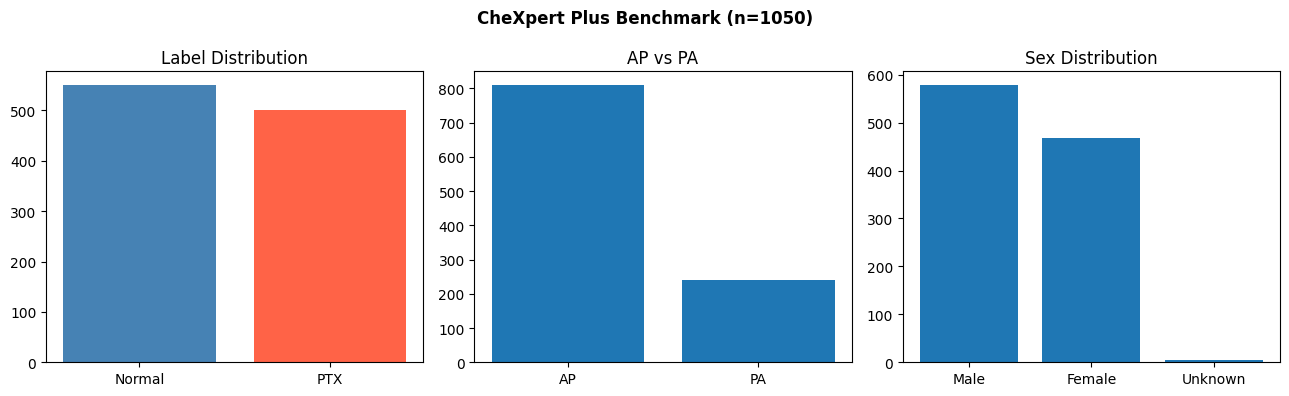

Saved.


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].bar(['Normal', 'PTX'], [(df.label==0).sum(), (df.label==1).sum()], color=['steelblue','tomato'])
axes[0].set_title('Label Distribution')
ap_pa = df.ap_pa.value_counts()
axes[1].bar(ap_pa.index, ap_pa.values)
axes[1].set_title('AP vs PA')
sex = df.sex.value_counts()
axes[2].bar(sex.index, sex.values)
axes[2].set_title('Sex Distribution')
plt.suptitle('CheXpert Plus Benchmark (n=1050)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(DATASET_OUT / 'subset_distribution.png', dpi=150)
plt.show()

df.to_csv(DATASET_OUT / 'subset_chexpert_plus.csv', index=False)
print('Saved.')